In [45]:
import pandas as pd

df = pd.read_csv("train.csv")

df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [47]:
df=df.loc[:, 'Gender':'satisfaction']

In [48]:
df["satisfaction"] = df["satisfaction"].map({"neutral or dissatisfied": 0, "satisfied": 1})

In [49]:
print(df["satisfaction"].value_counts())

satisfaction
0    58879
1    45025
Name: count, dtype: int64


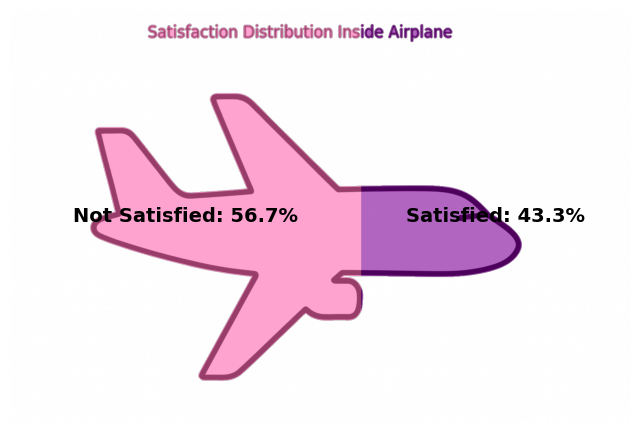

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage as ndi
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu
from skimage.morphology import dilation, disk

img = mpimg.imread("airplane.png")

gray = rgb2gray(img)

th = threshold_otsu(gray)
edge_mask = gray < th

edge_mask = dilation(edge_mask, disk(2))

filled_mask = ndi.binary_fill_holes(edge_mask)

H, W = filled_mask.shape

counts = df['satisfaction'].value_counts(normalize=True)
p0 = round(counts.get(0, 0.0) * 100, 1)
p1 = round(counts.get(1, 0.0) * 100, 1)

overlay = np.zeros((H, W, 4), dtype=np.float32)

split_x = int(W * (p0 / 100))

mask_0 = filled_mask.copy()
mask_0[:, split_x:] = False
overlay[mask_0] = [1.0, 0.4, 0.7, 0.6]

mask_1 = filled_mask.copy()
mask_1[:, :split_x] = False
overlay[mask_1] = [0.5, 0.0, 0.6, 0.6]


fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img)
ax.imshow(overlay)

ax.text(split_x / 2, H / 2, f'Not Satisfied: {p0}%',
        fontsize=14, ha='center', va='center', weight='bold')

ax.text((split_x + W) / 2, H / 2, f'Satisfied: {p1}%',
        fontsize=14, ha='center', va='center', weight='bold')

ax.axis('off')
#plt.title("Satisfaction Distribution Inside Airplane")
plt.show()


In [51]:
categorical_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]

numeric_cols = [
    "Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes",
    "Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
    "Gate location", "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness"
]

In [52]:
df.isnull().sum()

,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0


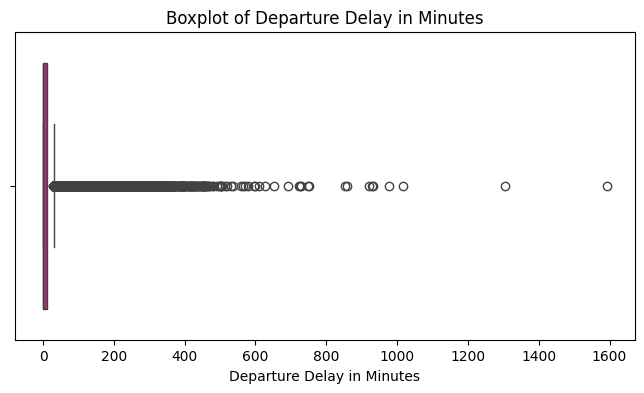

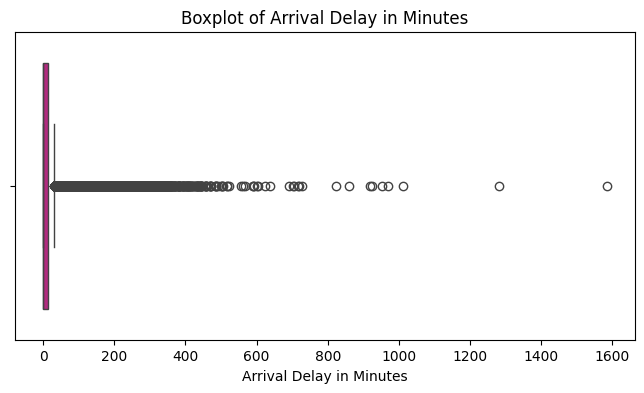

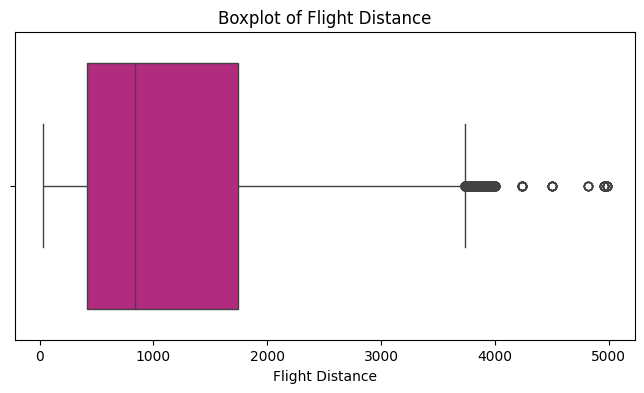

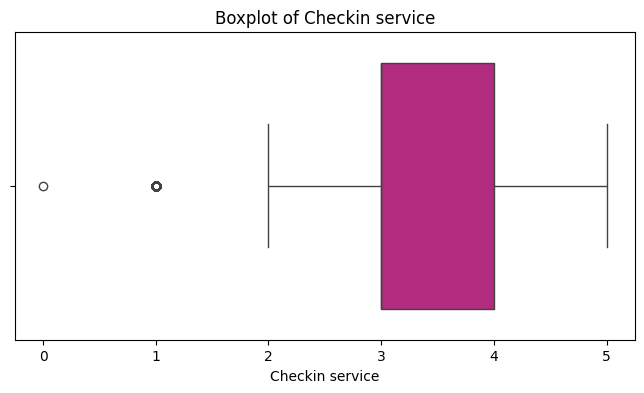

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_cols = ['Departure Delay in Minutes','Arrival Delay in Minutes', 'Flight Distance','Checkin service']

for col in selected_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col], color="#C71585")
    plt.title(f"Boxplot of {col}")
    plt.show()


In [54]:
import pandas as pd

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [55]:

print(df.isnull().sum())

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64


In [56]:
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [71]:
from sklearn.model_selection import train_test_split

X = df.drop("satisfaction", axis=1)
y = df["satisfaction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [72]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [79]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
roc_auc = roc_auc_score(y_test, y_proba)

print("=== Model Performance Summary ===\n")
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-score: {f1}")
print(f"ROC AUC Score: {roc_auc}")


=== Model Performance Summary ===

Accuracy: 0.8778633301251203
Precision: 0.8776182558819021
Recall: 0.8778633301251203
F1-score: 0.8775453211160522
ROC AUC Score: 0.928935564014314


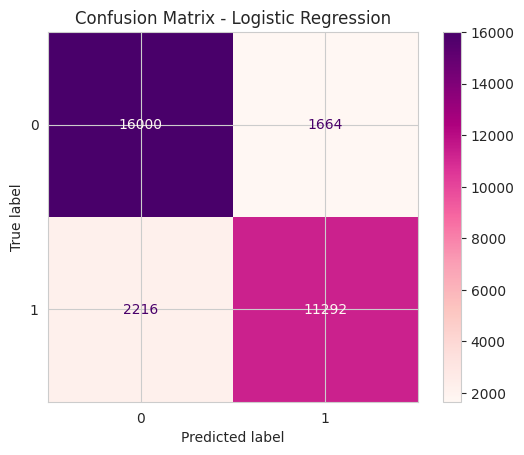

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='RdPu')
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [62]:
import pandas as pd

train_df = pd.read_csv("train.csv")
test_df  = pd.read_csv("test.csv")

full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

print(full_df.shape)



(129880, 25)


In [78]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

kf = KFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, average='weighted'),
    'recall': make_scorer(recall_score, average='weighted'),
    'f1': make_scorer(f1_score, average='weighted'),
    'roc_auc': 'roc_auc'
}

cv_results = cross_validate(model, X, y, cv=kf, scoring=scoring)

print("10-Fold Accuracy scores:", cv_results['test_accuracy'])
print("10-Fold Precision scores:", cv_results['test_precision'])
print("10-Fold Recall scores:", cv_results['test_recall'])
print("10-Fold F1-score scores:", cv_results['test_f1'])
print("10-Fold ROC AUC scores:", cv_results['test_roc_auc'])

print("\n=== Average Cross Validation Scores ===")
print("Average Accuracy:", np.mean(cv_results['test_accuracy']))
print("Average Precision:", np.mean(cv_results['test_precision']))
print("Average Recall:", np.mean(cv_results['test_recall']))
print("Average F1-score:", np.mean(cv_results['test_f1']))
print("Average ROC AUC:", np.mean(cv_results['test_roc_auc']))


10-Fold Accuracy scores: [0.87604658 0.87758637 0.87133096 0.87614282 0.86997113 0.87545717
 0.87516843 0.8761309  0.87516843 0.87786333]
10-Fold Precision scores: [0.87601142 0.87744841 0.8712464  0.87613612 0.86982361 0.87532821
 0.87494633 0.87595385 0.87515162 0.87761826]
10-Fold Recall scores: [0.87604658 0.87758637 0.87133096 0.87614282 0.86997113 0.87545717
 0.87516843 0.8761309  0.87516843 0.87786333]
10-Fold F1-score scores: [0.87566311 0.87734581 0.87098205 0.87578461 0.86965713 0.87513615
 0.87485269 0.87585344 0.8747472  0.87754532]
10-Fold ROC AUC scores: [0.92487515 0.93003376 0.92365703 0.92694578 0.92401902 0.92629814
 0.92854077 0.92765395 0.92599407 0.92893556]

=== Average Cross Validation Scores ===
Average Accuracy: 0.8750866110998364
Average Precision: 0.8749664231209417
Average Recall: 0.8750866110998364
Average F1-score: 0.874756751905349
Average ROC AUC: 0.9266953223352232


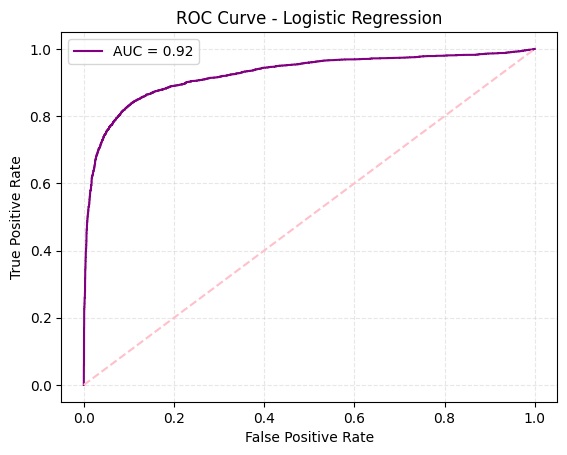

In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.linear_model import LogisticRegression

y_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color='purple', label="AUC = %0.2f" % roc_auc)
plt.plot([0, 1], [0, 1], color='pink', linestyle='--')  # خط التوقع العشوائي

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

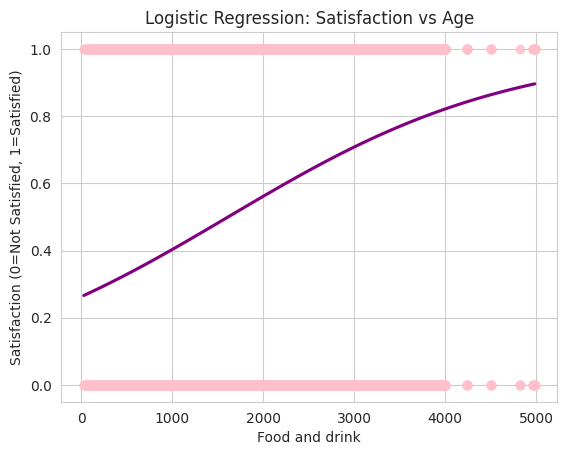

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

sns.regplot(
    x='Flight Distance',
    y='satisfaction',
    data=df,
    logistic=True,
    ci=None,
    scatter_kws={'color':'pink'},
    line_kws={'color':'purple'}
)

plt.title("Logistic Regression: Satisfaction vs Age")
plt.xlabel("Food and drink")
plt.ylabel("Satisfaction (0=Not Satisfied, 1=Satisfied)")
plt.show()